In [52]:
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score,recall_score,f1_score,
    confusion_matrix,classification_report,roc_auc_score,
    roc_curve
)
  
import warnings
warnings.filterwarnings('ignore')

In [53]:
df = pd.read_csv( r'C:\Users\priya\OneDrive\Desktop\machine-learning\dataset.zip')

In [54]:
df

,LoanID,Age,Income,LoanAmount,CreditScore,MonthsEmployed,NumCreditLines,InterestRate,LoanTerm,DTIRatio,Education,EmploymentType,MaritalStatus,HasMortgage,HasDependents,LoanPurpose,HasCoSigner,Default
0,I38PQUQS96,56,85994,50587,520,80,4,15.23,36,0.44,Bachelor's,Full-time,Divorced,Yes,Yes,Other,Yes,0
1,HPSK72WA7R,69,50432,124440,458,15,1,4.81,60,0.68,Master's,Full-time,Married,No,No,Other,Yes,0
2,C1OZ6DPJ8Y,46,84208,129188,451,26,3,21.17,24,0.31,Master's,Unemployed,Divorced,Yes,Yes,Auto,No,1
3,V2KKSFM3UN,32,31713,44799,743,0,3,7.07,24,0.23,High School,Full-time,Married,No,No,Business,No,0
4,EY08JDHTZP,60,20437,9139,633,8,4,6.51,48,0.73,Bachelor's,Unemployed,Divorced,No,Yes,Auto,No,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
255342,8C6S86ESGC,19,37979,210682,541,109,4,14.11,12,0.85,Bachelor's,Full-time,Married,No,No,Other,No,0
255343,98R4KDHNND,32,51953,189899,511,14,2,11.55,24,0.21,High School,Part-time,Divorced,No,No,Home,No,1
255344,XQK1UUUNGP,56,84820,208294,597,70,3,5.29,60,0.50,High School,Self-employed,Married,Yes,Yes,Auto,Yes,0
255345,JAO28CPL4H,42,85109,60575,809,40,1,20.90,48,0.44,High School,Part-time,Single,Yes,Yes,Other,No,0


In [55]:
for i in df.select_dtypes(include=object).columns:
    print(df[i].unique())

['I38PQUQS96' 'HPSK72WA7R' 'C1OZ6DPJ8Y' ... 'XQK1UUUNGP' 'JAO28CPL4H'
 'ZTH91CGL0B']
["Bachelor's" "Master's" 'High School' 'PhD']
['Full-time' 'Unemployed' 'Self-employed' 'Part-time']
['Divorced' 'Married' 'Single']
['Yes' 'No']
['Yes' 'No']
['Other' 'Auto' 'Business' 'Home' 'Education']
['Yes' 'No']


In [56]:
df.head()

,LoanID,Age,Income,LoanAmount,CreditScore,MonthsEmployed,NumCreditLines,InterestRate,LoanTerm,DTIRatio,Education,EmploymentType,MaritalStatus,HasMortgage,HasDependents,LoanPurpose,HasCoSigner,Default
0,I38PQUQS96,56,85994,50587,520,80,4,15.23,36,0.44,Bachelor's,Full-time,Divorced,Yes,Yes,Other,Yes,0
1,HPSK72WA7R,69,50432,124440,458,15,1,4.81,60,0.68,Master's,Full-time,Married,No,No,Other,Yes,0
2,C1OZ6DPJ8Y,46,84208,129188,451,26,3,21.17,24,0.31,Master's,Unemployed,Divorced,Yes,Yes,Auto,No,1
3,V2KKSFM3UN,32,31713,44799,743,0,3,7.07,24,0.23,High School,Full-time,Married,No,No,Business,No,0
4,EY08JDHTZP,60,20437,9139,633,8,4,6.51,48,0.73,Bachelor's,Unemployed,Divorced,No,Yes,Auto,No,0


In [57]:
df.tail()

,LoanID,Age,Income,LoanAmount,CreditScore,MonthsEmployed,NumCreditLines,InterestRate,LoanTerm,DTIRatio,Education,EmploymentType,MaritalStatus,HasMortgage,HasDependents,LoanPurpose,HasCoSigner,Default
255342,8C6S86ESGC,19,37979,210682,541,109,4,14.11,12,0.85,Bachelor's,Full-time,Married,No,No,Other,No,0
255343,98R4KDHNND,32,51953,189899,511,14,2,11.55,24,0.21,High School,Part-time,Divorced,No,No,Home,No,1
255344,XQK1UUUNGP,56,84820,208294,597,70,3,5.29,60,0.50,High School,Self-employed,Married,Yes,Yes,Auto,Yes,0
255345,JAO28CPL4H,42,85109,60575,809,40,1,20.90,48,0.44,High School,Part-time,Single,Yes,Yes,Other,No,0
255346,ZTH91CGL0B,62,22418,18481,636,113,2,6.73,12,0.48,Bachelor's,Unemployed,Divorced,Yes,No,Education,Yes,0


In [58]:
df.shape

(255347, 18)

In [59]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 255347 entries, 0 to 255346
Data columns (total 18 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   LoanID          255347 non-null  object 
 1   Age             255347 non-null  int64  
 2   Income          255347 non-null  int64  
 3   LoanAmount      255347 non-null  int64  
 4   CreditScore     255347 non-null  int64  
 5   MonthsEmployed  255347 non-null  int64  
 6   NumCreditLines  255347 non-null  int64  
 7   InterestRate    255347 non-null  float64
 8   LoanTerm        255347 non-null  int64  
 9   DTIRatio        255347 non-null  float64
 10  Education       255347 non-null  object 
 11  EmploymentType  255347 non-null  object 
 12  MaritalStatus   255347 non-null  object 
 13  HasMortgage     255347 non-null  object 
 14  HasDependents   255347 non-null  object 
 15  LoanPurpose     255347 non-null  object 
 16  HasCoSigner     255347 non-null  object 
 17  Default   

In [60]:
df.isnull().sum()


LoanID            0
Age               0
Income            0
LoanAmount        0
CreditScore       0
MonthsEmployed    0
NumCreditLines    0
InterestRate      0
LoanTerm          0
DTIRatio          0
Education         0
EmploymentType    0
MaritalStatus     0
HasMortgage       0
HasDependents     0
LoanPurpose       0
HasCoSigner       0
Default           0
dtype: int64

In [61]:
"Duplicates:", df.duplicated().sum()

('Duplicates:', np.int64(0))

In [62]:
df.drop_duplicates(inplace=True)

In [63]:
df.drop('LoanID', axis=1, inplace=True)

In [64]:
df.describe()

,Age,Income,LoanAmount,CreditScore,MonthsEmployed,NumCreditLines,InterestRate,LoanTerm,DTIRatio,Default
count,255347.000000,255347.000000,255347.000000,255347.000000,255347.000000,255347.000000,255347.000000,255347.000000,255347.000000,255347.000000
mean,43.498306,82499.304597,127578.865512,574.264346,59.541976,2.501036,13.492773,36.025894,0.500212,0.116128
std,14.990258,38963.013729,70840.706142,158.903867,34.643376,1.117018,6.636443,16.969330,0.230917,0.320379
min,18.000000,15000.000000,5000.000000,300.000000,0.000000,1.000000,2.000000,12.000000,0.100000,0.000000
25%,31.000000,48825.500000,66156.000000,437.000000,30.000000,2.000000,7.770000,24.000000,0.300000,0.000000
50%,43.000000,82466.000000,127556.000000,574.000000,60.000000,2.000000,13.460000,36.000000,0.500000,0.000000
75%,56.000000,116219.000000,188985.000000,712.000000,90.000000,3.000000,19.250000,48.000000,0.700000,0.000000
max,69.000000,149999.000000,249999.000000,849.000000,119.000000,4.000000,25.000000,60.000000,0.900000,1.000000


In [65]:
df.select_dtypes(include='object').columns

Index(['Education', 'EmploymentType', 'MaritalStatus', 'HasMortgage',
       'HasDependents', 'LoanPurpose', 'HasCoSigner'],
      dtype='object')

In [66]:
df.to_csv('cleaned_loan_dataset.csv', index=False)

In [67]:
df

,Age,Income,LoanAmount,CreditScore,MonthsEmployed,NumCreditLines,InterestRate,LoanTerm,DTIRatio,Education,EmploymentType,MaritalStatus,HasMortgage,HasDependents,LoanPurpose,HasCoSigner,Default
0,56,85994,50587,520,80,4,15.23,36,0.44,Bachelor's,Full-time,Divorced,Yes,Yes,Other,Yes,0
1,69,50432,124440,458,15,1,4.81,60,0.68,Master's,Full-time,Married,No,No,Other,Yes,0
2,46,84208,129188,451,26,3,21.17,24,0.31,Master's,Unemployed,Divorced,Yes,Yes,Auto,No,1
3,32,31713,44799,743,0,3,7.07,24,0.23,High School,Full-time,Married,No,No,Business,No,0
4,60,20437,9139,633,8,4,6.51,48,0.73,Bachelor's,Unemployed,Divorced,No,Yes,Auto,No,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
255342,19,37979,210682,541,109,4,14.11,12,0.85,Bachelor's,Full-time,Married,No,No,Other,No,0
255343,32,51953,189899,511,14,2,11.55,24,0.21,High School,Part-time,Divorced,No,No,Home,No,1
255344,56,84820,208294,597,70,3,5.29,60,0.50,High School,Self-employed,Married,Yes,Yes,Auto,Yes,0
255345,42,85109,60575,809,40,1,20.90,48,0.44,High School,Part-time,Single,Yes,Yes,Other,No,0


In [68]:
df.describe()

,Age,Income,LoanAmount,CreditScore,MonthsEmployed,NumCreditLines,InterestRate,LoanTerm,DTIRatio,Default
count,255347.000000,255347.000000,255347.000000,255347.000000,255347.000000,255347.000000,255347.000000,255347.000000,255347.000000,255347.000000
mean,43.498306,82499.304597,127578.865512,574.264346,59.541976,2.501036,13.492773,36.025894,0.500212,0.116128
std,14.990258,38963.013729,70840.706142,158.903867,34.643376,1.117018,6.636443,16.969330,0.230917,0.320379
min,18.000000,15000.000000,5000.000000,300.000000,0.000000,1.000000,2.000000,12.000000,0.100000,0.000000
25%,31.000000,48825.500000,66156.000000,437.000000,30.000000,2.000000,7.770000,24.000000,0.300000,0.000000
50%,43.000000,82466.000000,127556.000000,574.000000,60.000000,2.000000,13.460000,36.000000,0.500000,0.000000
75%,56.000000,116219.000000,188985.000000,712.000000,90.000000,3.000000,19.250000,48.000000,0.700000,0.000000
max,69.000000,149999.000000,249999.000000,849.000000,119.000000,4.000000,25.000000,60.000000,0.900000,1.000000


<Axes: xlabel='Default'>

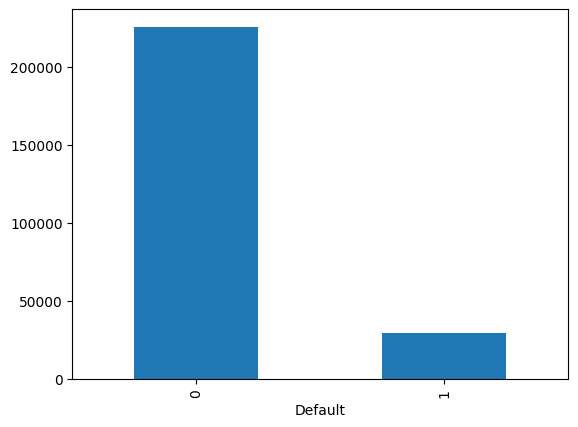

In [69]:
df['Default'].value_counts().plot(kind='bar')

In [70]:
df.select_dtypes(exclude='object').columns


Index(['Age', 'Income', 'LoanAmount', 'CreditScore', 'MonthsEmployed',
       'NumCreditLines', 'InterestRate', 'LoanTerm', 'DTIRatio', 'Default'],
      dtype='object')

In [71]:
df.columns

Index(['Age', 'Income', 'LoanAmount', 'CreditScore', 'MonthsEmployed',
       'NumCreditLines', 'InterestRate', 'LoanTerm', 'DTIRatio', 'Education',
       'EmploymentType', 'MaritalStatus', 'HasMortgage', 'HasDependents',
       'LoanPurpose', 'HasCoSigner', 'Default'],
      dtype='object')

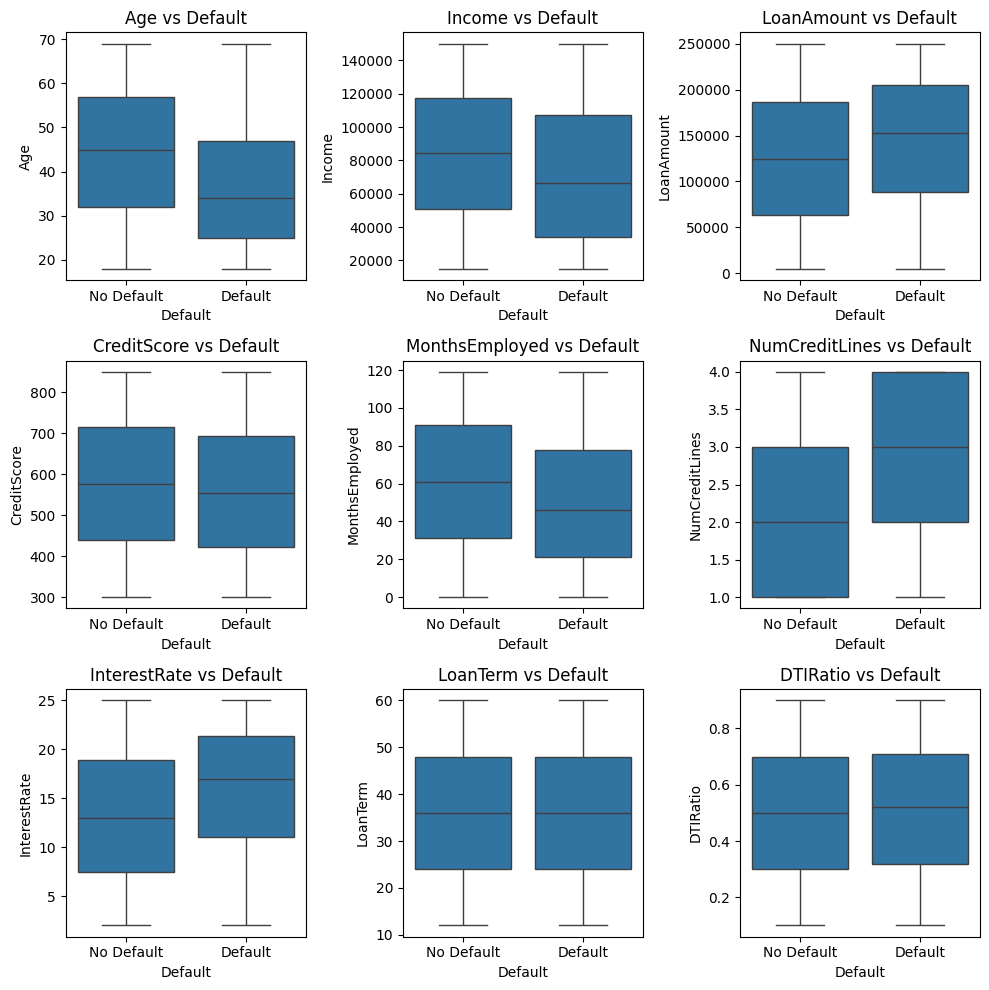

In [72]:
numerical_cols=['Age', 'Income', 'LoanAmount', 'CreditScore', 'MonthsEmployed',
       'NumCreditLines', 'InterestRate', 'LoanTerm', 'DTIRatio']

fig, axs=plt.subplots(3,3,figsize=(10,10))
axs=axs.flatten()
for index, column_name in enumerate(numerical_cols):
       sns.boxplot(data=df,y=column_name,x='Default',ax=axs[index])
       axs[index].set_title(f'{column_name} vs Default')
       axs[index].set_xticklabels(['No Default','Default'])
       plt.tight_layout()
   


<Axes: >

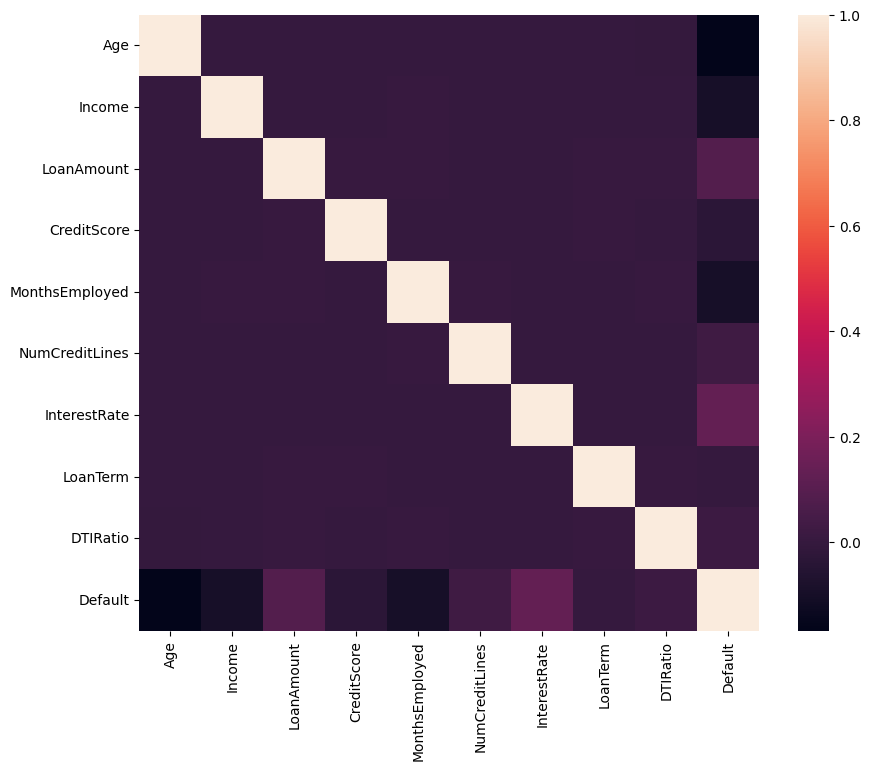

In [73]:
#correlation

plt.figure(figsize=(10,8))
sns.heatmap(df[numerical_cols+['Default']].corr())

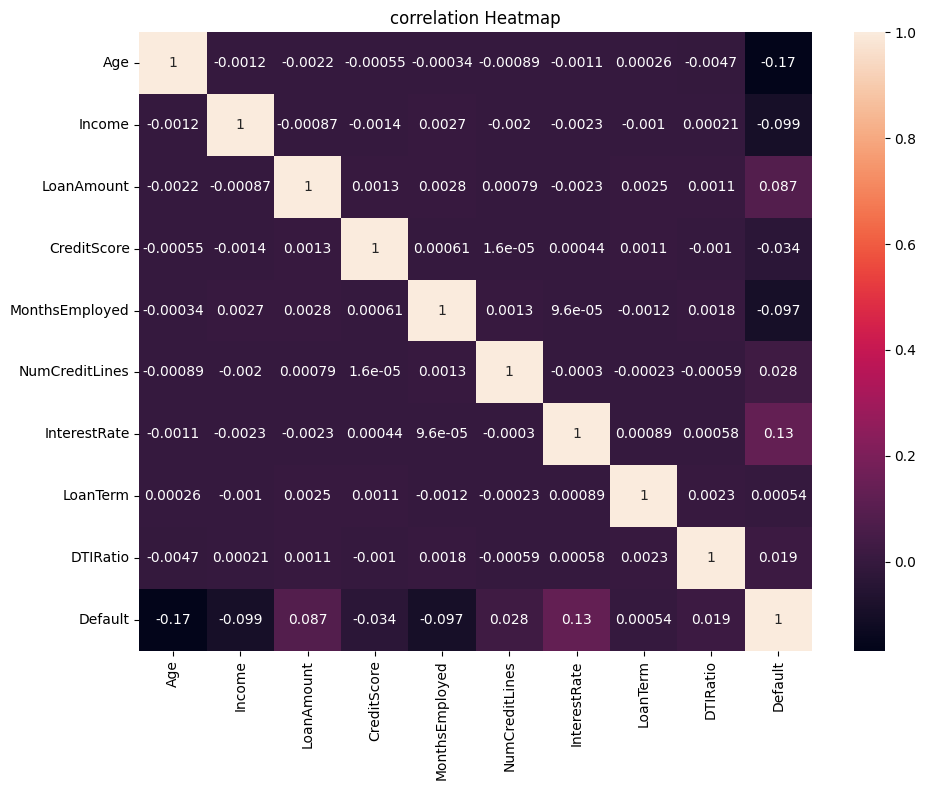

In [74]:
plt.figure(figsize=(10,8))
sns.heatmap(df[numerical_cols+['Default']].corr(),annot=True)
plt.title('correlation Heatmap')
plt.tight_layout()
plt.show()

In [24]:
#data preprocessing

In [75]:
X= df.drop('Default',axis=1)
Y= df['Default']

In [76]:
categorical_column=X.select_dtypes(include='object').columns.to_list()
numerical_column=X.select_dtypes(exclude='object').columns.to_list()
label_encoders={}

for col in categorical_column:
    le= LabelEncoder()
    X[col]=le.fit_transform(X[col].astype(object))
    print(f'encoded {col}: {dict(zip(le.classes_, le.transform(le.classes_)))}''')

encoded Education: {"Bachelor's": np.int64(0), 'High School': np.int64(1), "Master's": np.int64(2), 'PhD': np.int64(3)}
encoded EmploymentType: {'Full-time': np.int64(0), 'Part-time': np.int64(1), 'Self-employed': np.int64(2), 'Unemployed': np.int64(3)}
encoded MaritalStatus: {'Divorced': np.int64(0), 'Married': np.int64(1), 'Single': np.int64(2)}
encoded HasMortgage: {'No': np.int64(0), 'Yes': np.int64(1)}
encoded HasDependents: {'No': np.int64(0), 'Yes': np.int64(1)}
encoded LoanPurpose: {'Auto': np.int64(0), 'Business': np.int64(1), 'Education': np.int64(2), 'Home': np.int64(3), 'Other': np.int64(4)}
encoded HasCoSigner: {'No': np.int64(0), 'Yes': np.int64(1)}


In [77]:
X

,Age,Income,LoanAmount,CreditScore,MonthsEmployed,NumCreditLines,InterestRate,LoanTerm,DTIRatio,Education,EmploymentType,MaritalStatus,HasMortgage,HasDependents,LoanPurpose,HasCoSigner
0,56,85994,50587,520,80,4,15.23,36,0.44,0,0,0,1,1,4,1
1,69,50432,124440,458,15,1,4.81,60,0.68,2,0,1,0,0,4,1
2,46,84208,129188,451,26,3,21.17,24,0.31,2,3,0,1,1,0,0
3,32,31713,44799,743,0,3,7.07,24,0.23,1,0,1,0,0,1,0
4,60,20437,9139,633,8,4,6.51,48,0.73,0,3,0,0,1,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
255342,19,37979,210682,541,109,4,14.11,12,0.85,0,0,1,0,0,4,0
255343,32,51953,189899,511,14,2,11.55,24,0.21,1,1,0,0,0,3,0
255344,56,84820,208294,597,70,3,5.29,60,0.50,1,2,1,1,1,0,1
255345,42,85109,60575,809,40,1,20.90,48,0.44,1,1,2,1,1,4,0


In [78]:
x_train, x_test, y_train , y_test= train_test_split(
    X,Y,test_size=0.2,random_state=22
)

In [79]:
scaler = StandardScaler()

X_train_scaled=x_train.copy()
X_test_scaled=x_test.copy()

X_train_scaled[numerical_cols]=scaler.fit_transform(x_train[numerical_column])

X_test_scaled[numerical_cols]=scaler.fit_transform(x_test[numerical_column])

In [37]:
X_train_scaled

,Age,Income,LoanAmount,CreditScore,MonthsEmployed,NumCreditLines,InterestRate,LoanTerm,DTIRatio,Education,EmploymentType,MaritalStatus,HasMortgage,HasDependents,LoanPurpose,HasCoSigner
61239,43,62684,68258,801,15,3,17.71,48,0.69,2,3,2,1,1,0,1
205826,62,70551,136268,649,22,4,20.74,36,0.82,1,0,2,1,0,3,1
72979,32,135306,72857,574,102,4,3.25,36,0.20,0,0,1,0,1,4,0
155879,49,97182,87119,314,79,3,12.71,36,0.80,0,1,0,1,0,2,0
154184,56,110634,70947,742,36,1,11.27,36,0.45,3,3,1,1,0,2,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
24932,32,125473,180080,525,49,1,22.81,12,0.65,0,0,1,0,0,0,1
162752,21,121522,144275,839,79,3,11.32,48,0.54,3,1,2,0,1,0,1
226092,44,116975,232360,679,34,2,10.90,12,0.78,1,3,2,0,1,3,1
252036,44,76494,225239,617,96,3,10.62,60,0.69,1,1,2,1,0,3,0


In [91]:
lr= LogisticRegression(class_weight='balanced',
max_iter=100,solver='saga',n_jobs=-1)
lr.fit(X_train_scaled,y_train)
y_pred=lr.predict(X_test_scaled)
y_pred_proba=lr.predict(X_test_scaled)

In [39]:
from sklearn.metrics import (ConfusionMatrixDisplay,
classification_report,accuracy_score,
precision_score,recall_score,roc_curve,roc_auc_score)

In [104]:
print(f'accuracy_score: {accuracy_score(y_test,y_pred)}')
print(f'precision_score: {precision_score(y_test,y_pred)}')
print(f'recall_score: {recall_score(y_test.y_pred)}')
print(f'f1_score: {f1_score(y_test,y_pred_proba)}')
print(f'roc auc score: {roc_auc_score(y_test,y_pred_proba)}')

accuracy_score: 0.6736048560798904
precision_score: 0.21706040906928808


AttributeError: 'Series' object has no attribute 'y_pred'

In [81]:
print(classification_report(y_test,y_pred,
target_names=['No default' , 'Default']))

              precision    recall  f1-score   support

  No default       0.92      0.61      0.73     45108
     Default       0.16      0.57      0.25      5962

    accuracy                           0.61     51070
   macro avg       0.54      0.59      0.49     51070
weighted avg       0.83      0.61      0.68     51070



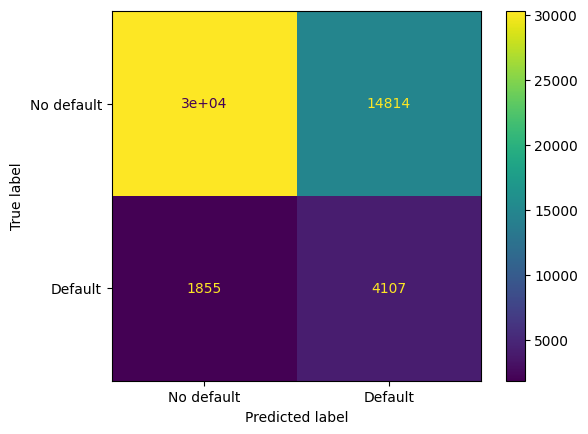

In [102]:
cm= confusion_matrix(y_test,y_pred)

dis= ConfusionMatrixDisplay(confusion_matrix=cm,
display_labels=['No default' , 'Default'])
dis.plot()
plt.show()

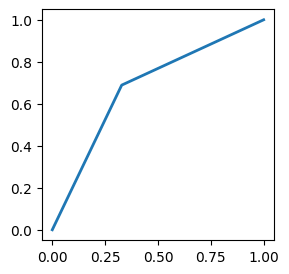

In [103]:
fpr, tpr ,  thresholds = roc_curve(y_test, y_pred_proba)
plt.figure(figsize=(3,3))
plt.plot(fpr, tpr , lw=2)

In [47]:
coef_df=pd.DataFrame({
    'Columns' :x_train.columns,
    'cofficient':lr.coef_[0]
}).sort_values(by='cofficient', key=abs,ascending=False)

In [42]:
coef_df

,Columns,cofficient
0,Age,-8.274046e-04
1,Income,-5.860295e-06
2,LoanAmount,4.357898e-06
3,CreditScore,-1.313516e-04
4,MonthsEmployed,-1.046985e-03
5,NumCreditLines,1.755032e-05
6,InterestRate,3.629339e-04
7,LoanTerm,9.352227e-05
8,DTIRatio,3.029852e-06
9,Education,-5.453558e-06


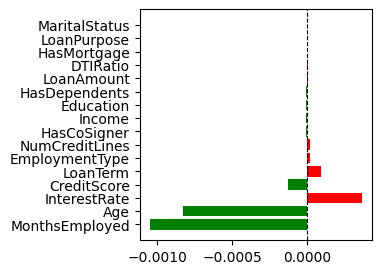

In [50]:
plt.figure(figsize=(3,3))
color=['r' if c >0 else 'g' for c in coef_df['cofficient']]
plt.barh(coef_df['Columns'], coef_df['cofficient'],color=color)
plt.axvline(x=0 , color='black' , linewidth=0.8 , linestyle='--')
plt.show()

In [98]:
#from statsmodels.stats.nonparametric
import joblib

joblib.dump(lr,'logistic_regression.pkl')

['logistic_regression.pkl']

In [99]:
model=joblib.load('logistic_regression.pkl')

In [100]:
model.predict(x_test.iloc[:2,:])

array([1, 1])